<a href="https://colab.research.google.com/github/NilsChabloz/2026_Intro_Python/blob/main/live/part-I/1.3-numpy-environmental-exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-I/1.3-numpy-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"gsw": "gsw", "pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import numpy as `np`, and encode units in your variable names.

## Exercise 1: Ocean float profiles

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/argo-float-cycle.png" alt="A diagram of one Argo float cycle, numbered one to seven, from deployment through drift, dive, ascent and satellite transmission" width="100%">

<em>One cycle of an Argo float: deployment, descent to a drifting depth of about 1000 m, ten days of
drift, a dive to the profiling depth, then the ascent during which the measurements are taken, and
transmission to satellite at the surface before the next cycle begins. The panel on the right shows
what one ascent produces — the temperature and salinity profiles you are about to work with.
Illustration &copy; Thomas Haessig, from
<a href="https://www.euro-argo.eu/Outreach/Educational-material/Discover-Argo-floats-for-kids/How-do-the-Argo-floats-fulfill-their-mission-in-the-Ocean">Euro-Argo ERIC's educational material</a>.</em>


[Argo](https://argo.ucsd.edu/) floats are autonomous instruments that drift with ocean currents,
periodically diving and surfacing while recording temperature, salinity, and pressure. Each dive
produces one *profile*: a set of measurements at many depth *levels*, with a single latitude,
longitude, and date attached.

This exercise uses real Argo data. Steps 1 to 8 use only what 1.1 to 1.3 cover: loading
arrays, inspecting shapes, rebuilding an axis, vectorised arithmetic, reductions along an axis,
boolean masks, and NaN-aware statistics. Steps 9 to 11 then plot what you computed.

**ℹ️ Beyond this subchapter**

Steps 9 to 11 use `matplotlib`, which gets its own treatment in 1.4. Import it once with
`import matplotlib.pyplot as plt`; after that you need only the functions below, and each is
named again where it is wanted:

- `plt.figure()` — start a new, empty figure; without it, every plot in a cell lands on the
  same axes
- [`plt.plot`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html) — a line, or
  one line per column when handed a 2D array
- [`plt.errorbar`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.errorbar.html) — a
  line with error bars
- [`plt.scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) — points
- `plt.xlabel`, `plt.ylabel`, `plt.title` — each takes a string
- `plt.show()` — draw the current figure

An array of numbers with no picture attached is hard to sanity-check, which is why these three
steps sit here rather than waiting for 1.4: the profiles are the fastest way to see whether Steps 4
to 6 produced something physical.

In [2]:
# Pre-supplied: download and unzip the Argo data files.
import pooch

files = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/argo_float_data.zip",
    known_hash="sha256:dd913ba3450241bcd5d5697187ea68d398bdd7fd563a04cc74386834749c25f5",
    processor=pooch.Unzip(),
    path=pooch.os_cache("mlees"),
)
for f in sorted(files):
    print(f)

Unzipping contents of '/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip' to '/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip'


/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/P.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/S.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/T.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/date.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/lat.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/levels.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/lon.npy


**Step 1.** Load each `.npy` file into a numpy array with `np.load`. Name them `T` (temperature,
°C), `S` (practical salinity, unitless), `P` (pressure, dbar), `date`, `lat`, `lon`, and `level` (depth level).

Read the filenames printed above to work out which file is which.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

temp_c = np.load('/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/T.npy')
salt = np.load('/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/S.npy')
pressure_dbar = np.load('/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/P.npy')
date = np.load('/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/date.npy')
lat = np.load('/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/lat.npy')
lon = np.load('/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/lon.npy')
level = np.load('/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/levels.npy')
# Hint: every file sits in the same folder, Path(files[0]).parent (Path comes from pathlib)
# Hint: join a filename onto that folder with /, as in Path("_files") / "station_daily.csv"
# Hint: np.load(path) returns the array stored in a .npy file

**Step 2.** Print the `shape` of every array you loaded. Then answer in a comment: which
dimension do `T`, `S`, and `P` share with `level`, and which do they share with `lat`, `lon`,
and `date`?

In [4]:
print('Temperature shape:', temp_c.shape)
print('Salinity shape:', salt.shape)
print('Pressure shape:', pressure_dbar.shape)
print('Levels shape:', level.shape)
print('Date shape:', date.shape)
print('Latitude shape:', lat.shape)
print('Longitude shape:', lon.shape)

# T, S, and P share axis 0 with Levels and axis 1 with Date, Latitude, Longitude.

# Hint: the profile arrays are two-dimensional; the coordinate arrays are one-dimensional
# Hint: a 2D array's shape tells you the length of each axis — match those against the 1D shapes

Temperature shape: (78, 75)
Salinity shape: (78, 75)
Pressure shape: (78, 75)
Levels shape: (78,)
Date shape: (75,)
Latitude shape: (75,)
Longitude shape: (75,)


**Step 3.** The `level` array is a regular sequence. Recreate it twice — once with `np.arange`
and once with `np.linspace` — and confirm each matches the original using `np.allclose`.

Read `level[0]`, `level[-1]`, and `level.size` first to work out the arguments.

In [5]:
level_aranged = np.arange(0, 78, 1)

level_linspaced = np.linspace(0, 77, 78)

print('Is np.linspace matching the original:', np.allclose(level_linspaced, level))
print('Is np.arange matching the original:', np.allclose(level_aranged, level))

print('Level[0] =', level[0], ', Level[-1] =', level[-1], ', Level.size =', level.size)
# Hint: np.arange(start, stop, step) excludes the stop value
# Hint: np.linspace(start, stop, num) includes both ends
# Hint: np.allclose(a, b) returns True when every pair of elements is close enough

Is np.linspace matching the original: True
Is np.arange matching the original: True
Level[0] = 0 , Level[-1] = 77 , Level.size = 78


**Step 4.** Compute the density of seawater relative to pure water, in kg m⁻³:

$$\rho - \rho_{\text{pure water}} = a\,S + b\,\Theta + c\,\Theta^{2}$$

where $S$ is salinity and $\Theta$ is the *conservative* temperature, computed from
temperature, salinity, and pressure by the `gsw` library. The constants are

```python
a = 7.718e-1
b = -8.44e-2
c = -4.561e-3
```

The cell below imports the function. Compute `conservative_temp` and `relative_density`, print
the shape of your result, and check it matches `T`.

Both `CT_from_t` and the formula expect *absolute* salinity, in g/kg, while Argo reports
*practical* salinity, which has no unit. Absolute salinity is about 0.5 % larger; for these
profiles, using practical salinity in its place lowers every relative density by about
0.13 kg m⁻³, which is small enough to ignore here. `gsw.SA_from_SP` does the exact conversion
when it matters.

Source: Roquet et al. (2015), *J. Phys. Oceanogr.* 45, 2564–2579, and the
[TEOS-10 GSW toolbox](https://www.teos-10.org/).

In [6]:
# Pre-supplied: the conservative-temperature function from the gsw library
from gsw import CT_from_t

In [7]:
cons_temp = CT_from_t(salt, temp_c, pressure_dbar)

a = 7.718e-1
b = -8.44e-2
c = -4.561e-3

rel_density = (a*salt + b*cons_temp + c*cons_temp**2) + 1000

print('Conservative temperature shape:', cons_temp.shape)
print('Relative density shape:', rel_density.shape)
print('Temperature shape for comparison:', temp_c.shape)

# Hint: CT_from_t(SA, t, p) takes salinity, temperature, and pressure — in that order
# Hint: the whole formula is one vectorised expression; no loop is needed
# Hint: Theta**2 squares every element

Conservative temperature shape: (78, 75)
Relative density shape: (78, 75)
Temperature shape for comparison: (78, 75)


**Step 5.** Compute the mean and the standard deviation of `T`, `S`, `P`, and
`relative_density` **at each depth**, averaging across all the profiles.

Check your result has the same shape as `level` — if it does not, you reduced along the wrong
axis.

In [8]:
t_mean = np.nanmean(temp_c, axis = 1)
t_std = np.nanstd(temp_c, axis = 1)

s_mean = np.nanmean(salt, axis = 1)
s_std = np.nanstd(salt, axis = 1)

p_mean = np.nanmean(pressure_dbar, axis = 1)
p_std = np.nanstd(pressure_dbar, axis = 1)
# Hint: pick the axis that runs across profiles, not across depths
# Hint: mean_T.shape should equal level.shape

**Step 6.** Look at the mean you just computed. Many entries are `nan`, because Argo profiles
contain missing values and an ordinary mean propagates them.

1. Count how many values in `T` are missing, using `np.isnan` and a sum over the boolean mask.
2. Express that as a percentage of all values in `T`.
3. Recompute the mean and standard deviation with `np.nanmean` and `np.nanstd`, and confirm no
   `nan` remains.

In [9]:
# 1.
missing_t = np.isnan(temp_c)
count = missing_t.sum()
print(count)

# 2.
ratio_t = count / temp_c.size * 100
print(ratio_t)

# 3.
print(np.isnan(t_mean).sum(), np.isnan(t_std).sum())
# Hint: np.isnan(T) gives a boolean array; True counts as 1 when summed
# Hint: T.size is the total number of elements
# Hint: np.isnan(result).sum() counts the nan that survived; it should be 0

101
1.7264957264957266
0 0


**Step 7.** Using `np.where`, build an array that labels each depth `"warm"` where the mean
temperature there is above 10 °C and `"cold"` otherwise. Print the first ten labels alongside
the first ten depths.

Then, using a boolean mask, print the depths at which the mean temperature is below 5 °C.

In [15]:
temp_classified = np.where(t_mean > 10 , 'warm', 'cold')
print(temp_classified[:10], level[:10])

print(level[t_mean<5.0])
# Hint: np.where(condition, value_if_true, value_if_false) works element-wise
# Hint: level[mask] selects the depths where the mask is True

['warm' 'warm' 'warm' 'warm' 'warm' 'warm' 'warm' 'warm' 'warm' 'warm'] [0 1 2 3 4 5 6 7 8 9]
[63 64 65 66 67 68 69 70 71 72 73 74 75 76 77]


**Step 8.** Assemble a summary array with `np.vstack`: one row of depths, one of mean
temperature, one of mean salinity, and one of mean relative density — four rows in total.

Print its shape, save it to `_files/argo_summary.npy`, load it back, and confirm with `np.allclose`
that the round trip changed nothing.

In [24]:
summary = np.vstack([level, t_mean, s_mean, np.nanmean(rel_density, axis = 1)])
print(summary.shape)

from pathlib import Path

Path('_files').mkdir(exist_ok = True)
np.save('_files/argo_summary.npy', summary)
reloaded = np.load('_files/argo_summary.npy')
np.allclose(summary, reloaded)

# Hint: np.vstack takes a list of 1D arrays and stacks them as rows
# Hint: your summary should have shape (4, n_levels)
# Hint: _files/ may not exist yet; create it first with Path("_files").mkdir(exist_ok=True)

(4, 78)


True

**Step 9.** Plot each of `T`, `S`, `P` and `relative_density` against depth — four figures, one
per variable.

Each array is `(level, profile)`, so handing the whole array to `plt.plot` draws one line per
profile. Put the variable on the *x*-axis and `level` on the *y*-axis, which is the oceanographic
convention: depth runs down the page, and a profile is read the way the float measured it.

It will look messy, because 75 profiles are drawn on top of each other.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.3-target-argo-profiles.png" alt="Many overlapping salinity profiles plotted against depth level, forming a dense band that shifts towards fresher water with depth" width="500">

<em>The salinity panel, as a check on yours. Label the axes and give each figure a title.</em>

ValueError: not enough values to unpack (expected 4, got 2)

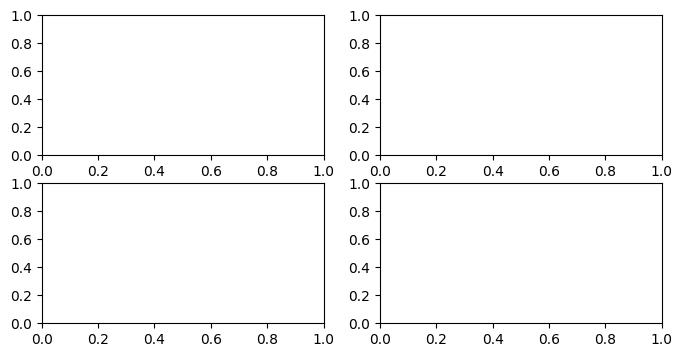

In [45]:
fig, axes = plt.subplots(figsize=(8, 4), nrows=2, ncols=2)
ax0, ax1, ax2, ax3 = axes

ax0.plot(temp_c, level)
ax0.set_xlabel('Temperature (in °C)')
ax0.set_ylabel('Depth Level')
ax0.set_title('Temperature profiles at different locations')

ax1.plot(salt, level)
ax1.set_xlabel('Salinity (in g/kg)')
ax1.set_ylabel('Depth Level')
ax1.set_title('Salinity profiles at different locations')

# squeeze everything in
plt.tight_layout()
plt.show()

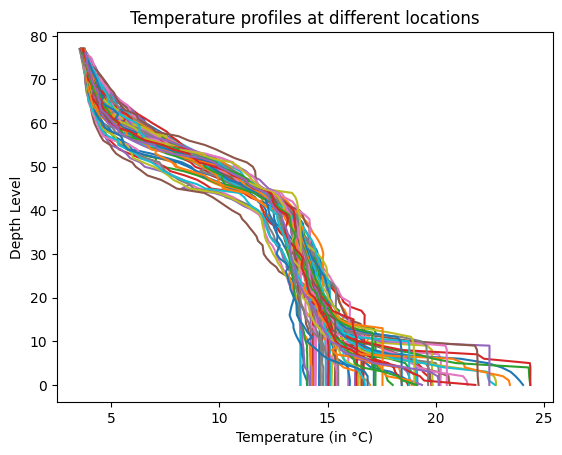

In [27]:
plt.figure()
plt.plot(temp_c, level)
plt.ylabel('Depth Level'), plt.xlabel('Temperature (in °C)'), plt.title('Temperature profiles at different locations')
plt.show()
# Hint: plt.figure() before each variable's plot, plt.show() after it
# Hint: plt.plot(S, level) draws one line per column of S
# Hint: the semicolon at the end of a plt.plot call suppresses the list of line objects
# Hint: plt.xlabel, plt.ylabel and plt.title each take a string

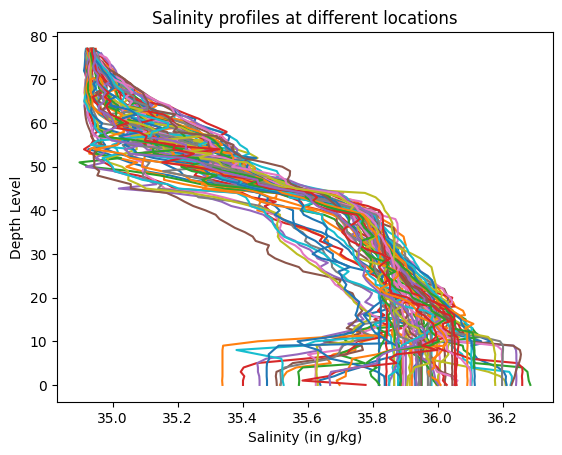

In [29]:
plt.figure()
plt.plot(salt, level)
plt.ylabel('Depth Level'), plt.xlabel('Salinity (in g/kg)'), plt.title('Salinity profiles at different locations')
plt.show()
# Hint: plt.figure() before each variable's plot, plt.show() after it
# Hint: plt.plot(S, level) draws one line per column of S
# Hint: the semicolon at the end of a plt.plot call suppresses the list of line objects
# Hint: plt.xlabel, plt.ylabel and plt.title each take a string

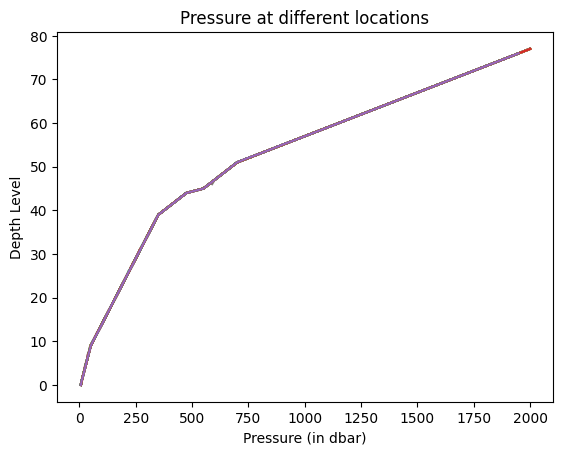

In [31]:
plt.figure()
plt.plot(pressure_dbar, level)
plt.ylabel('Depth Level'), plt.xlabel('Pressure (in dbar)'), plt.title('Pressure at different locations')
plt.show()
# Hint: plt.figure() before each variable's plot, plt.show() after it
# Hint: plt.plot(S, level) draws one line per column of S
# Hint: the semicolon at the end of a plt.plot call suppresses the list of line objects
# Hint: plt.xlabel, plt.ylabel and plt.title each take a string

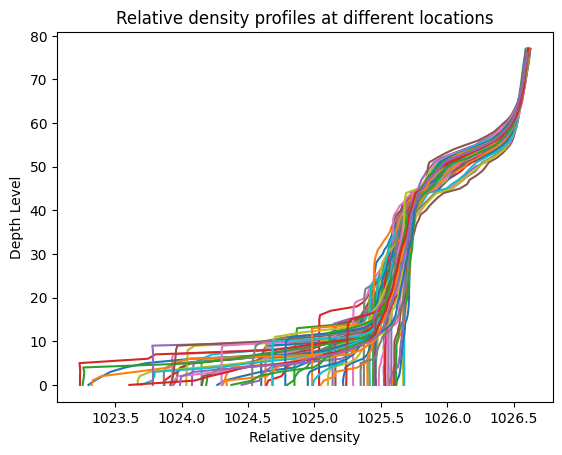

In [32]:
plt.figure()
plt.plot(rel_density, level)
plt.ylabel('Depth Level'), plt.xlabel('Relative density'), plt.title('Relative density profiles at different locations')
plt.show()
# Hint: plt.figure() before each variable's plot, plt.show() after it
# Hint: plt.plot(S, level) draws one line per column of S
# Hint: the semicolon at the end of a plt.plot call suppresses the list of line objects
# Hint: plt.xlabel, plt.ylabel and plt.title each take a string

**Step 10.** Now plot only the *mean* profile of each variable, with the standard deviation as
error bars.

Use the NaN-aware mean and standard deviation from Step 6, and draw them with `plt.errorbar`.
Because the variable is on the *x*-axis, the spread is a *horizontal* error bar — the keyword is
`xerr`, not `yerr`.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.3-target-argo-mean-profiles.png" alt="A single mean salinity profile against depth level with horizontal error bars at each level" width="500">

<em>The salinity panel again, reduced from 75 profiles to one line and its spread.</em>


In a comment, say what the width of the error bars tells you about how much the profiles disagree
near the surface compared with at depth.

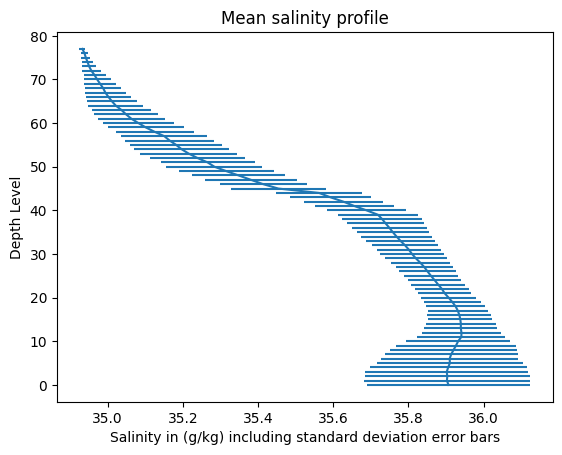

In [42]:
plt.figure()
plt.errorbar(s_mean, level, xerr=s_std)
plt.xlabel('Salinity in (g/kg) including standard deviation error bars'), plt.ylabel('Depth Level'), plt.title('Mean salinity profile')
plt.show()
# Hint: plt.errorbar(mean_S, level, xerr=std_S)
# Hint: use the nan-aware versions from Step 6, or every bar will be missing

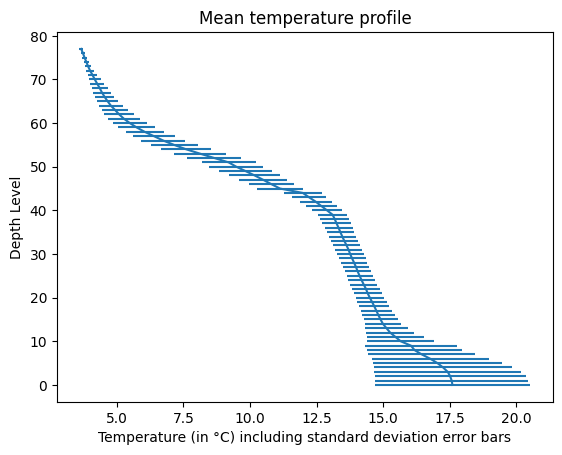

In [41]:
plt.figure()
plt.errorbar(t_mean, level, xerr=t_std)
plt.xlabel('Temperature (in °C) including standard deviation error bars'), plt.ylabel('Depth Level'), plt.title('Mean temperature profile')
plt.show()
# Hint: plt.errorbar(mean_S, level, xerr=std_S)
# Hint: use the nan-aware versions from Step 6, or every bar will be missing

In [ ]:
plt.figure()
plt.errorbar(t_mean, level, xerr=t_std)
plt.xlabel('Temperature (in °C) including standard deviation error bars'), plt.ylabel('Depth Level'), plt.title('Mean temperature profile')
plt.show()
# Hint: plt.errorbar(mean_S, level, xerr=std_S)
# Hint: use the nan-aware versions from Step 6, or every bar will be missing

**Step 11.** Scatter the profiles' longitudes against their latitudes.

One point per profile. Label both axes and give it a title, and set the marker size with `s=` so
the points are readable. Then print the first three entries of `date` and the last one.

In a comment, say what the dates and the shape of the cloud tell you about how this set of
profiles was collected, and by how many floats.

In [14]:
# Your solution here
# Hint: plt.scatter(lon, lat)
# Hint: lon and lat have one entry per profile, not per level
# Hint: look at the spacing between consecutive dates

**ℹ️ What you just did**

You loaded a real oceanographic dataset, worked out its structure from the array shapes alone,
rebuilt a coordinate axis and verified it, evaluated a published equation of state as one
vectorised expression over 5,850 measurements (78 depth levels by 75 profiles), reduced along the
right axis, counted the missing values and switched to NaN-aware statistics, and saved a derived
product.

None of the computation needed a loop over the data. In the next subchapter `xarray` attaches the
names (depth, profile, latitude) to the axes you have been tracking by hand, and `matplotlib` gets
its full treatment, including the line, error-bar and scatter plots you drew here.